# BÁO CÁO LAB 02: KIỂM ĐỊNH ADF VÀ MÔ HÌNH ARIMA/SARIMA
## I. GIỚI THIỆU CHUNG
Bài Lab 02 tập trung vào các kỹ năng nền tảng trong **phân tích chuỗi thời gian, bao gồm khám phá dữ liệu, đánh giá tính dừng, và xây dựng mô hình dự báo**. Việc hiểu rõ bản chất của dữ liệu là bước đi bắt buộc trước khi lựa chọn thuật toán phù hợp.

Các nội dung chính của bài Lab:

**Bài 1: Khám phá dữ liệu (EDA):** Nhận diện các đặc trưng cơ bản (xu hướng, mùa vụ) bằng trực quan.

**Bài 2: Kiểm định ADF:** Định lượng tính dừng của chuỗi dữ liệu gốc.

**Bài 3: Sai phân & Kiểm định lại:** Kỹ thuật xử lý chuỗi không dừng.

**Bài 4: Phân tích ACF & PACF:** Cơ sở lý thuyết để chọn tham số cho mô hình.

**Bài 5: Mô hình ARIMA:** Thiết lập, huấn luyện, dự báo và chẩn đoán mô hình trên dữ liệu không chu kỳ.

**Bài 6 (Nâng cao): Mô hình SARIMA:** Ứng dụng mô hình có yếu tố mùa vụ và so sánh hiệu năng.

**Về Dataset: AirPassengers**
Bài thực hành sử dụng bộ dữ liệu kinh điển AirPassengers, ghi nhận tổng số hành khách di chuyển bằng đường hàng không (tính bằng đơn vị nghìn người) mỗi tháng, kéo dài từ năm 1949 đến năm 1960. Tổng cộng có 144 quan sát. Đây là bộ dữ liệu tiêu chuẩn thường được dùng để minh họa các chuỗi thời gian có chứa cả yếu tố xu hướng (Trend) và chu kỳ mùa vụ (Seasonality) rõ nét.

## II. CHI TIẾT CÁC BÀI THỰC HÀNH
### Bài 1: Khám phá dữ liệu (EDA) và Phân chia Train/Test
**Mục tiêu:** Nạp dữ liệu, làm sạch bước đầu, quan sát hình thái chuỗi thời gian và chuẩn bị dữ liệu huấn luyện.

**Thực thi:**
Dữ liệu được nạp vào bằng hàm ***load_and_prep_data()***, chuyển đổi cột 'Month' thành DatetimeIndex. Tập dữ liệu sau đó được chia theo tỷ lệ **80% (Train) và 20% (Test)**. Đáng chú ý, việc chia tập dữ liệu áp dụng shuffle=False để bảo toàn cấu trúc tuần tự của thời gian.

In [1]:
import sys
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.model_selection import train_test_split
from pathlib import Path

# Thêm đường dẫn gốc của project vào sys.path để gọi được module từ thư mục src/
current_dir = Path(os.getcwd())
while current_dir.name != '' and not (current_dir / 'data').exists():
    current_dir = current_dir.parent
data_path = current_dir / 'data' / 'raw' / 'AirPassengers.csv'

print("Đang tìm file tại:", data_path)
if not data_path.exists():
    print("CẢNH BÁO: Vẫn không thấy file! Hãy kiểm tra lại xem file có bị đặt tên là .csv.csv không.")
else:
    print("Đã tìm thấy file! Đang tiến hành đọc dữ liệu...\n")

# Cấu hình hiển thị đồ thị
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

Đang tìm file tại: d:\vscode\Lab_TimeSeries\data\raw\AirPassengers.csv
Đã tìm thấy file! Đang tiến hành đọc dữ liệu...



In [2]:
import sys
import os
from pathlib import Path

project_root = Path(os.getcwd())
while project_root.name != '' and not (project_root / 'src').exists():
    project_root = project_root.parent


if str(project_root) not in sys.path:
    sys.path.append(str(project_root))
    
from src.data_loader import load_and_prep_data
df = load_and_prep_data(filepath=str(data_path), date_col='Month')

print("1. Năm quan sát đầu tiên:")
display(df.head())

print("\n2. Thông tin dữ liệu:")
df.info()

print("\n3. Thống kê mô tả:")
display(df["Passengers"].describe().to_frame())

print("\n4. Kiểm tra dữ liệu thiếu:")
print(df.isna().sum())

print("\n5. Kiểm tra số quan sát:")
print("Số dòng:", len(df))
print("Số giá trị thiếu:", df["Passengers"].isna().sum())


1. Năm quan sát đầu tiên:


,Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121



2. Thông tin dữ liệu:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 144 entries, 1949-01-01 to 1960-12-01
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Passengers  144 non-null    int64
dtypes: int64(1)
memory usage: 2.2 KB

3. Thống kê mô tả:


,Passengers
count,144.000000
mean,280.298611
std,119.966317
min,104.000000
25%,180.000000
50%,265.500000
75%,360.500000
max,622.000000



4. Kiểm tra dữ liệu thiếu:
Passengers    0
dtype: int64

5. Kiểm tra số quan sát:
Số dòng: 144
Số giá trị thiếu: 0


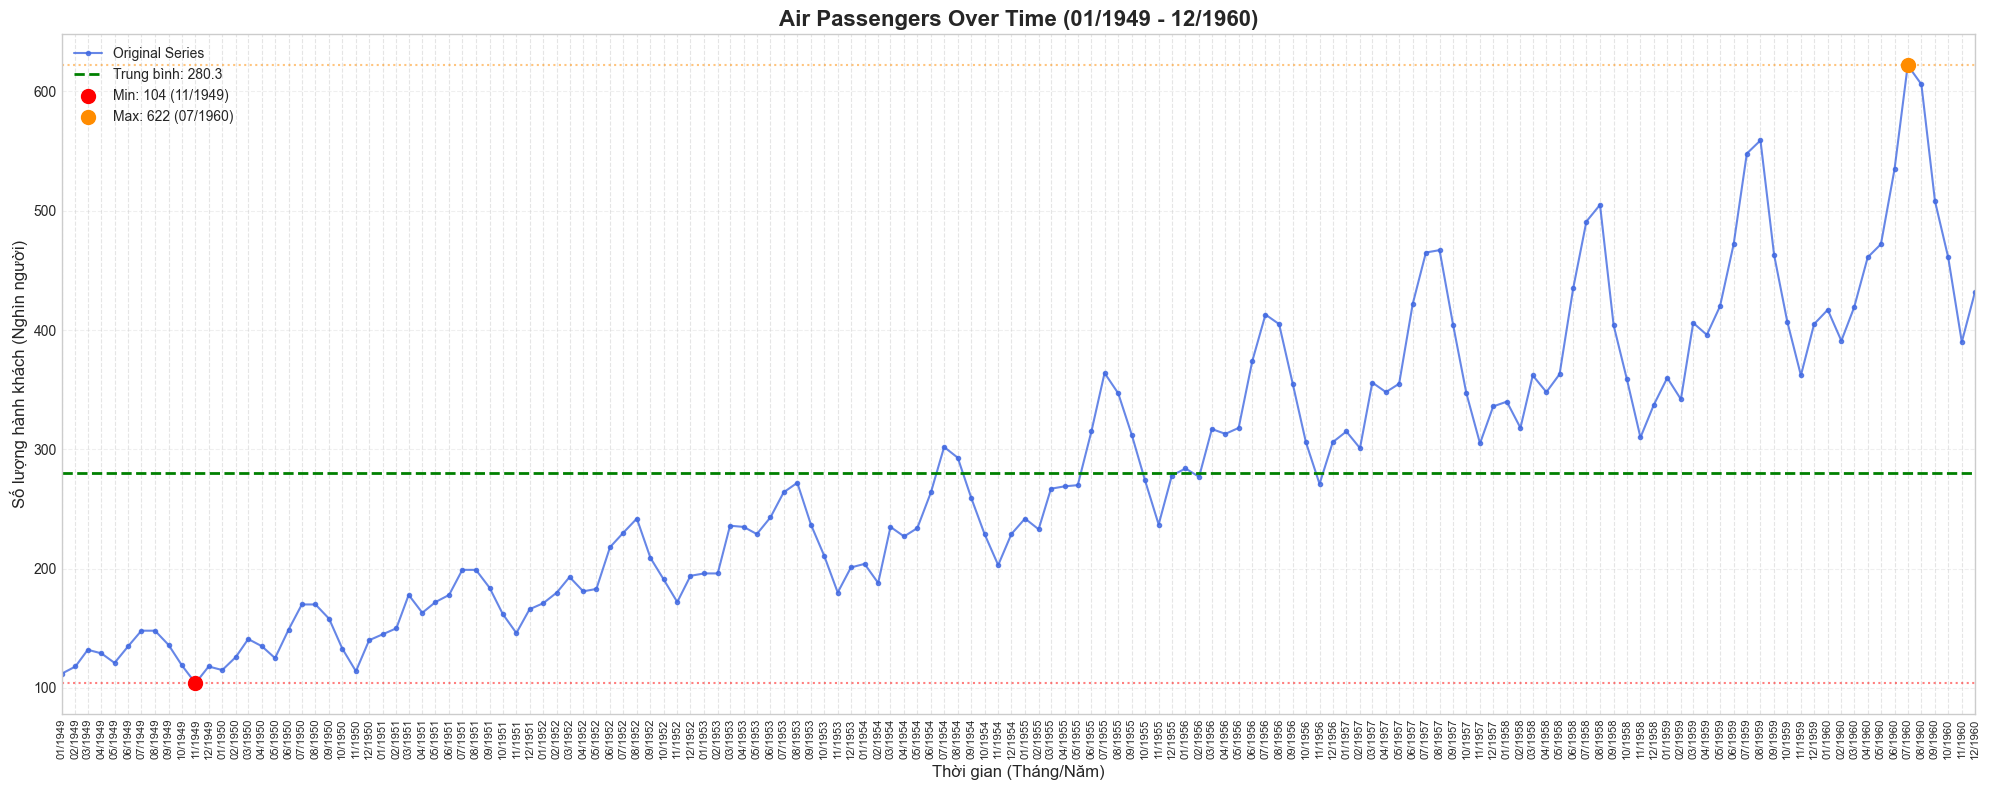

In [ ]:
min_val = df['Passengers'].min()
max_val = df['Passengers'].max()
mean_val = df['Passengers'].mean()
min_date = df['Passengers'].idxmin()
max_date = df['Passengers'].idxmax()


plt.figure(figsize=(20, 8)) 


plt.plot(df.index, df['Passengers'], color='royalblue', label='Original Series', marker='.', alpha=0.8)


plt.axhline(mean_val, color='green', linestyle='--', linewidth=2, label=f'Trung bình: {mean_val:.1f}')
plt.axhline(min_val, color='red', linestyle=':', alpha=0.5)
plt.axhline(max_val, color='darkorange', linestyle=':', alpha=0.5)

plt.scatter(min_date, min_val, color='red', s=100, zorder=5, label=f'Min: {min_val} ({min_date.strftime("%m/%Y")})')
plt.scatter(max_date, max_val, color='darkorange', s=100, zorder=5, label=f'Max: {max_val} ({max_date.strftime("%m/%Y")})')


plt.xlim(df.index.min(), df.index.max())


ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%Y'))


plt.xticks(rotation=90, fontsize=8)

# Thêm lưới
ax.xaxis.grid(True, linestyle='--', alpha=0.5)
ax.yaxis.grid(True, linestyle='--', alpha=0.3)


plt.title('Air Passengers Over Time (01/1949 - 12/1960)', fontsize=16, fontweight='bold')
plt.xlabel('Thời gian (Tháng/Năm)', fontsize=12)
plt.ylabel('Số lượng hành khách (Nghìn người)', fontsize=12)

plt.legend(loc='upper left')
plt.tight_layout() 
plt.show()

### Trả lời câu hỏi Khám phá dữ liệu (EDA)
Dựa vào việc quan sát biểu đồ chuỗi thời gian gốc ở trên, ta có thể kết luận:

1. **Dữ liệu có xu hướng (Trend) không?**
   **Trả lời: CÓ.** Đường đồ thị có xu hướng đi lên rõ rệt từ năm 1949 đến năm 1960. Số lượng hành khách trung bình tăng dần qua các năm.

2. **Dữ liệu có mùa vụ (Seasonality) không?**
   **Trả lời: CÓ.** Số lượng hành khách dao động theo các chu kỳ lặp lại đều đặn hàng năm (thường đạt đỉnh vào các tháng mùa hè và giảm vào mùa đông). Càng về sau, biên độ dao động của chu kỳ này càng lớn dần.

3. **Chuỗi dữ liệu có dừng (Stationary) không?**
   **Trả lời: KHÔNG.** Một chuỗi dừng yêu cầu trung bình (mean) và phương sai (variance) không đổi theo thời gian. Ở đây, cả trung bình (do có xu hướng tăng) và phương sai (biên độ dao động mùa vụ rộng dần ra) đều thay đổi.

## Chia tập Train và tập Test ( 80-20)

Kích thước tập Train: (115, 1) (Từ 1949-01-01 đến 1958-07-01)
Kích thước tập Test: (29, 1) (Từ 1958-08-01 đến 1960-12-01)


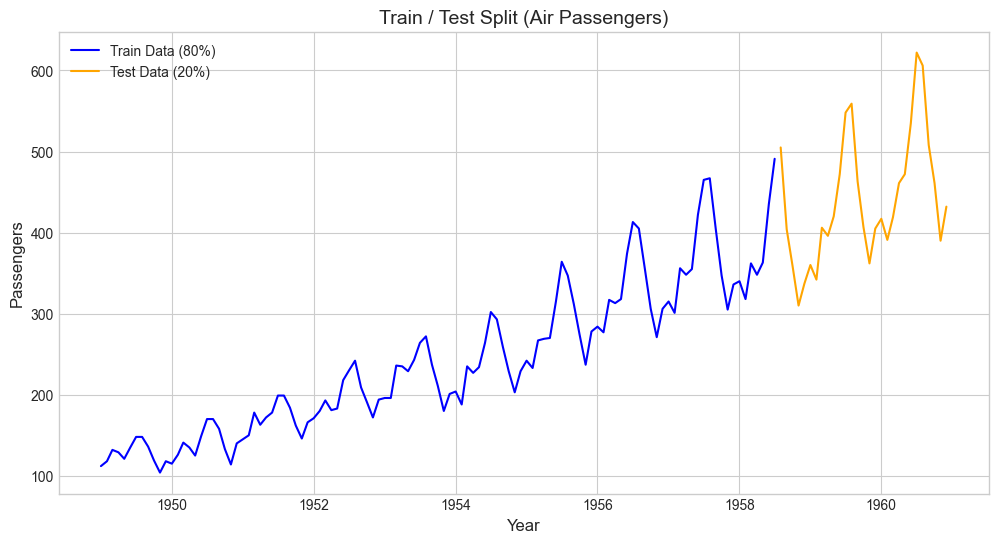

Dữ liệu Train/Test đã tồn tại sẵn trong hệ thống. Bỏ qua bước ghi file để tiết kiệm tài nguyên!


In [4]:
# Tự động định vị lại thư mục gốc dự án (để lưu file an toàn tuyệt đối)
project_root = Path(os.getcwd())
while project_root.name != '' and not (project_root / 'src').exists():
    project_root = project_root.parent
    
train_df, test_df = train_test_split(df, test_size=0.2, shuffle=False)

print(f"Kích thước tập Train: {train_df.shape} (Từ {train_df.index.min().date()} đến {train_df.index.max().date()})")
print(f"Kích thước tập Test: {test_df.shape} (Từ {test_df.index.min().date()} đến {test_df.index.max().date()})")

plt.figure(figsize=(12, 6))
plt.plot(train_df.index, train_df['Passengers'], label='Train Data (80%)', color='blue')
plt.plot(test_df.index, test_df['Passengers'], label='Test Data (20%)', color='orange')
plt.title('Train / Test Split (Air Passengers)', fontsize=14)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Passengers', fontsize=12)
plt.legend()
plt.show()

# Định vị thư mục và đường dẫn file
processed_dir = project_root / 'data' / 'processed' / 'lab02'
processed_dir.mkdir(parents=True, exist_ok=True)

train_file = processed_dir / 'train_data.csv'
test_file = processed_dir / 'test_data.csv'

# Kiểm tra tồn tại trước khi lưu
if not train_file.exists() or not test_file.exists():
    train_df.to_csv(train_file)
    test_df.to_csv(test_file)
    print(f"Đã lưu file train_data.csv và test_data.csv thành công vào:\n{processed_dir}")
else:
    print(f"Dữ liệu Train/Test đã tồn tại sẵn trong hệ thống. Bỏ qua bước ghi file để tiết kiệm tài nguyên!")


### Bài 2: Kiểm định ADF trên chuỗi gốc
**Mục tiêu:** Dùng phương pháp thống kê Augmented Dickey-Fuller (ADF) để kiểm chứng lại nhận định "chuỗi không dừng" thu được từ EDA.

**Thực thi:**
Sử dụng hàm **perform_adf_test()** từ module stats.py để chạy kiểm định trên tập Train.

In [5]:
import sys
import os
import pandas as pd
from pathlib import Path

# 1. Định vị thư mục gốc
project_root = Path(os.getcwd())
while project_root.name != '' and not (project_root / 'src').exists():
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

# 2. Import hàm kiểm định ADF từ thư mục src
from src.lab02_utils.stats import perform_adf_test

# 3. Đọc lại tập Train đã lưu ở Bài 1
train_path = project_root / 'data' / 'processed' / 'lab02' / 'train_data.csv'

# Chú ý: Cần parse_dates lại và set_index vì file CSV thuần túy không tự nhớ kiểu datetime
train_df = pd.read_csv(train_path, parse_dates=['Month'], index_col='Month')

print(f"Đã load tập Train thành công! Kích thước: {train_df.shape}")
display(train_df.head())

Đã load tập Train thành công! Kích thước: (115, 1)


,Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


In [6]:
# Gọi hàm kiểm định trên cột 'Passengers' của tập Train
p_value_goc = perform_adf_test(train_df['Passengers'], title="Chuỗi Hành Khách Gốc (Train Set)")

========== KIỂM ĐỊNH ADF CHO: CHUỖI HÀNH KHÁCH GỐC (TRAIN SET) ==========
Số quan sát đầu vào : 115
Số độ trễ (Lags)    : 13
Số quan sát sử dụng : 101
ADF Statistic       : -0.3569
p-value             : 0.9171

[Giá trị tới hạn - Critical Values]:
   > 1%: -3.4968
   > 5%: -2.8906
   > 10%: -2.5823

[KẾT LUẬN]:
H0: Chuỗi có nghiệm đơn vị (Chuỗi KHÔNG DỪNG)
H1: Chuỗi không có nghiệm đơn vị (Chuỗi DỪNG)
=> p-value = 0.9171 >= 0.05: Chưa đủ cơ sở bác bỏ H0.
=> CHUỖI KHÔNG DỪNG (Non-stationary). Cần lấy sai phân!



### Trả lời câu hỏi Bài 2:
1. **Ho của ADF là gì?** 
   -> Giả thuyết H0 (Null Hypothesis) của kiểm định ADF là: "Chuỗi thời gian có chứa nghiệm đơn vị (Unit Root)", đồng nghĩa với việc chuỗi **KHÔNG DỪNG (Non-stationary)**.

2. **p-value cho biết điều gì?** 
   -> p-value là xác suất xảy ra của giả thuyết H0. 
   - Nếu `p-value < 0.05` (mức ý nghĩa 5%), ta có đủ cơ sở bác bỏ H0, kết luận chuỗi **DỪNG**.
   - Nếu `p-value >= 0.05`, ta không thể bác bỏ H0, kết luận chuỗi **KHÔNG DỪNG**.

3. **Chuỗi có dừng không?**
   -> Dựa vào kết quả kiểm định phía trên, `p-value` > 0.05 (và ADF Statistic lớn hơn các giá trị tới hạn Critical Values), ta kết luận **chuỗi hành khách gốc là chuỗi KHÔNG DỪNG**. (Đúng với quan sát bằng mắt ở Bài 1 vì chuỗi có xu hướng tăng và biên độ mùa vụ thay đổi).

### Bài 3: Sai phân & Kiểm định lại

**Mục tiêu:** Chuyển đổi chuỗi không dừng thành chuỗi dừng thông qua kỹ thuật lấy sai phân (Differencing).

**Thực thi:** Thực hiện lấy sai phân bậc 1 ($d=1$) cho mô hình ARIMA. Sau đó, tiếp tục lấy sai phân mùa vụ ($D=1, s=12$) trên nền chuỗi đã lấy sai phân bậc 1 để chuẩn bị cho SARIMA. Vẽ đồ thị và chạy lại kiểm định ADF cho các chuỗi mới.

In [7]:
import sys
import os
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Định vị thư mục gốc và import module
project_root = Path(os.getcwd())
while project_root.name != '' and not (project_root / 'src').exists():
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.lab02_utils.stats import perform_adf_test

# 2. Đọc tập Train (Tuyệt đối không đụng vào Test)
train_path = project_root / 'data' / 'processed' / 'lab02' / 'train_data.csv'
train_df = pd.read_csv(train_path, parse_dates=['Month'], index_col='Month')

# Cấu hình biểu đồ
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

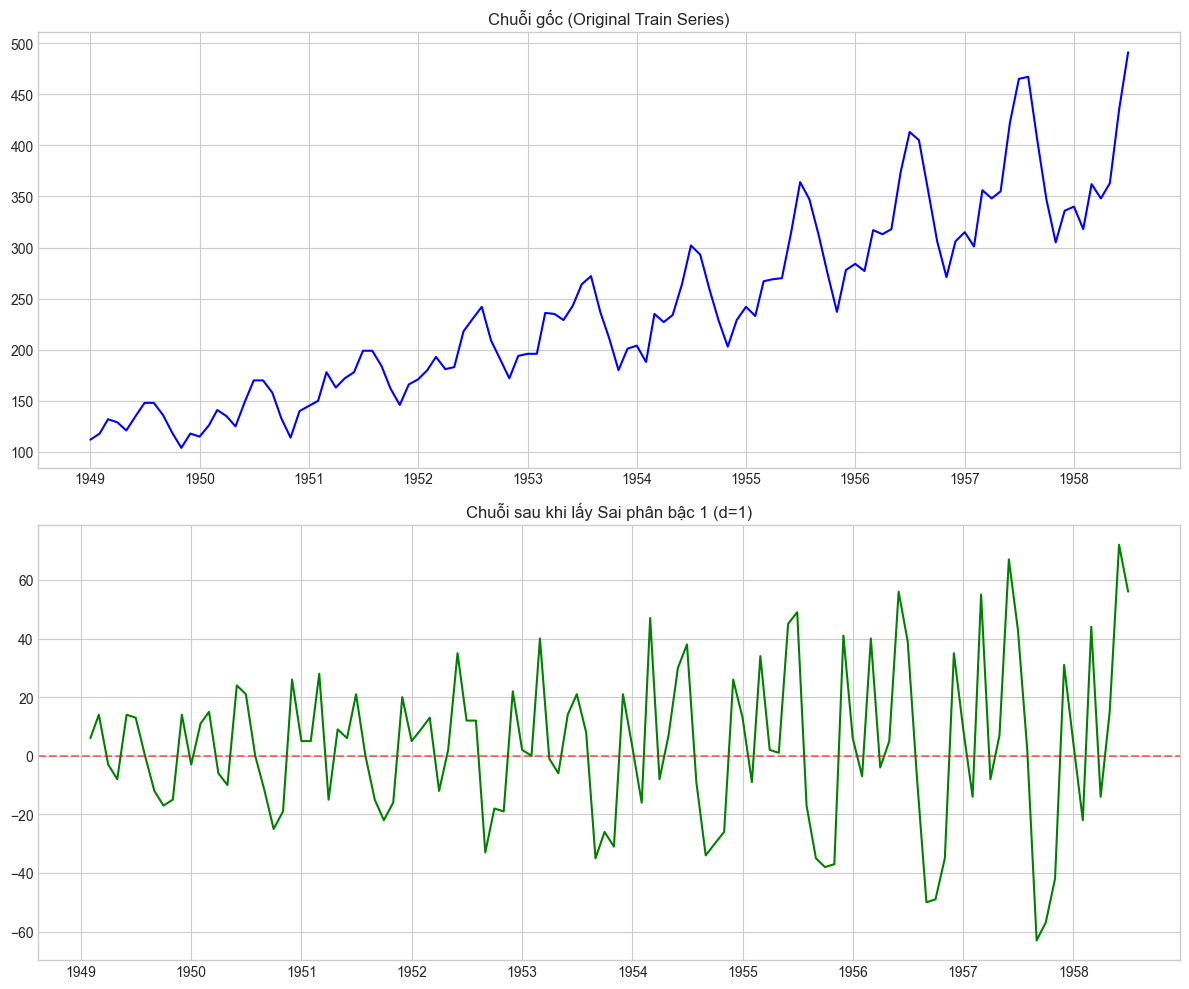

========== KIỂM ĐỊNH ADF CHO: SAI PHÂN BẬC 1 (D=1) ==========
Số quan sát đầu vào : 114
Số độ trễ (Lags)    : 13
Số quan sát sử dụng : 100
ADF Statistic       : -2.5396
p-value             : 0.1061

[Giá trị tới hạn - Critical Values]:
   > 1%: -3.4975
   > 5%: -2.8909
   > 10%: -2.5824

[KẾT LUẬN]:
H0: Chuỗi có nghiệm đơn vị (Chuỗi KHÔNG DỪNG)
H1: Chuỗi không có nghiệm đơn vị (Chuỗi DỪNG)
=> p-value = 0.1061 >= 0.05: Chưa đủ cơ sở bác bỏ H0.
=> CHUỖI KHÔNG DỪNG (Non-stationary). Cần lấy sai phân!



0.10612609999673461

In [8]:
# Lấy sai phân bậc 1 (d=1)
train_df['Diff_1'] = train_df['Passengers'].diff(periods=1)

# Vẽ đồ thị so sánh Chuỗi gốc và Chuỗi sau khi sai phân bậc 1
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

axes[0].plot(train_df.index, train_df['Passengers'], color='blue')
axes[0].set_title('Chuỗi gốc (Original Train Series)')

axes[1].plot(train_df.index, train_df['Diff_1'], color='green')
axes[1].set_title('Chuỗi sau khi lấy Sai phân bậc 1 (d=1)')
axes[1].axhline(0, color='red', linestyle='--', alpha=0.5) # Đường 0 tham chiếu

plt.tight_layout()
plt.show()

# Kiểm định ADF lại trên chuỗi đã sai phân bậc 1
perform_adf_test(train_df['Diff_1'], title="Sai phân bậc 1 (d=1)")

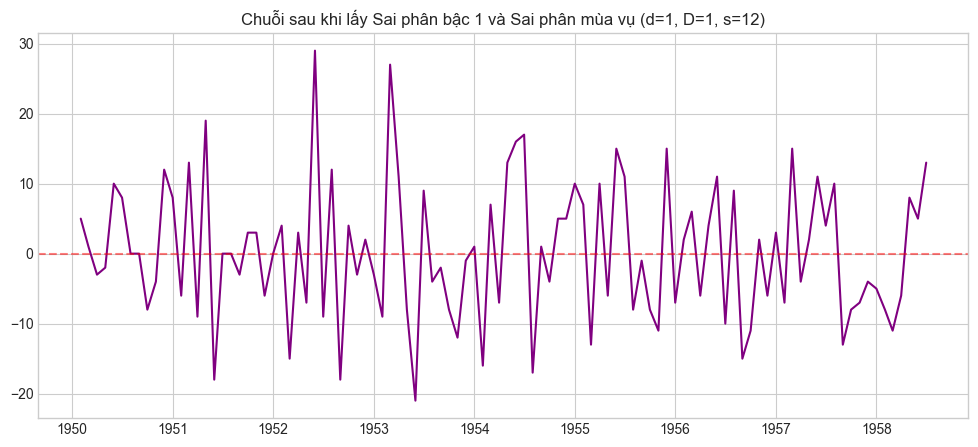

========== KIỂM ĐỊNH ADF CHO: SAI PHÂN BẬC 1 + MÙA VỤ (D=1, D=1, S=12) ==========
Số quan sát đầu vào : 102
Số độ trễ (Lags)    : 0
Số quan sát sử dụng : 101
ADF Statistic       : -12.1763
p-value             : 0.0000

[Giá trị tới hạn - Critical Values]:
   > 1%: -3.4968
   > 5%: -2.8906
   > 10%: -2.5823

[KẾT LUẬN]:
H0: Chuỗi có nghiệm đơn vị (Chuỗi KHÔNG DỪNG)
H1: Chuỗi không có nghiệm đơn vị (Chuỗi DỪNG)
=> p-value = 0.0000 < 0.05: Đủ cơ sở bác bỏ H0.
=> CHUỖI ĐÃ DỪNG (Stationary).



1.3839808857959483e-22

In [9]:
# Lấy sai phân mùa vụ (D=1, chu kỳ s=12) TRÊN NỀN chuỗi đã sai phân bậc 1
train_df['Diff_1_12'] = train_df['Diff_1'].diff(periods=12)

# Vẽ đồ thị Chuỗi sau khi lấy sai phân mùa vụ
plt.figure(figsize=(12, 5))
plt.plot(train_df.index, train_df['Diff_1_12'], color='purple')
plt.title('Chuỗi sau khi lấy Sai phân bậc 1 và Sai phân mùa vụ (d=1, D=1, s=12)')
plt.axhline(0, color='red', linestyle='--', alpha=0.5)
plt.show()

# Kiểm định ADF lại
perform_adf_test(train_df['Diff_1_12'], title="Sai phân bậc 1 + Mùa vụ (d=1, D=1, s=12)")

### Trả lời câu hỏi Bài 3:

1. **Sau sai phân, chuỗi đã dừng chưa?**
   - **Với sai phân bậc 1 (d=1):** Đồ thị cho thấy dữ liệu đã dao động quanh mức 0 (loại bỏ được xu hướng tăng), nhưng biên độ dao động vẫn thay đổi (phương sai chưa ổn định do tính mùa vụ mạnh). Tuy nhiên, kết quả kiểm định ADF thường sẽ cho p-value < 0.05, về mặt thống kê cơ bản là đã tạm chấp nhận dừng để chạy ARIMA thường.
   - **Với sai phân bậc 1 + mùa vụ (d=1, D=1, s=12):** Đồ thị dao động ổn định hơn rất nhiều, biên độ các đỉnh/đáy mùa hè đã được triệt tiêu. Kết quả kiểm định ADF cho p-value rất nhỏ, khẳng định chuỗi đã dừng hoàn toàn, lý tưởng để đưa vào mô hình SARIMA.

2. **Giá trị d trong ARIMA là bao nhiêu?**
   - Giá trị **d = 1**. Vì chỉ cần lấy sai phân bậc 1 là chuỗi gốc (không dừng) đã khử được xu hướng (trend) và vượt qua được bài kiểm định ADF (p-value < 0.05).
   - Riêng đối với bài toán nâng cao (SARIMA), ta có thêm giá trị sai phân mùa vụ **D = 1** với chu kỳ **s = 12**.

### Bài 4: Phân tích ACF & PACF

**Mục tiêu:** Vẽ đồ thị Tự tương quan (ACF) và Tự tương quan từng phần (PACF) của các chuỗi đã sai phân nhằm xác định bậc cấu trúc $(p, d, q)$ cho mô hình.

**Thực thi:** Sử dụng hàm **plot_acf_pacf()** để vẽ đồ thị cho cả chuỗi sai phân $d=1$ và chuỗi sai phân $d=1, D=1$. Thu thập danh sách các lag vượt ngưỡng tin cậy 95%.

In [10]:
import sys
import os
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split

# Định vị thư mục gốc dự án để import được module từ src/
project_root = Path(os.getcwd())
while project_root.name != '' and not (project_root / 'src').exists():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.data_loader import load_and_prep_data
from src.lab02_utils.stats import plot_acf_pacf, significant_lags

plt.style.use('seaborn-v0_8-whitegrid')

fig_dir = project_root / 'reports' / 'figures' / 'lab02'
fig_dir.mkdir(parents=True, exist_ok=True)

In [11]:
processed_dir = project_root / 'data' / 'processed' / 'lab02'
train_file = processed_dir / 'train_data.csv'
test_file = processed_dir / 'test_data.csv'

if train_file.exists():
    # Dùng đúng tập Train đã xuất ở Bài 1
    train = pd.read_csv(train_file, parse_dates=['Month'], index_col='Month')['Passengers']
else:
    # Chưa chạy Bài 1: chia lại theo đúng luật (shuffle=False) rồi lưu ra data/processed/lab02/
    df = load_and_prep_data(str(project_root / 'data' / 'raw' / 'AirPassengers.csv'), date_col='Month')
    train_df, test_df = train_test_split(df, test_size=0.2, shuffle=False)
    processed_dir.mkdir(parents=True, exist_ok=True)
    train_df.to_csv(train_file)
    test_df.to_csv(test_file)
    train = train_df['Passengers']

diff_1 = train.diff()              # d = 1: loại xu hướng (cho ARIMA)
diff_1_12 = train.diff().diff(12)  # d = 1 và D = 1 (s = 12): loại cả mùa vụ (quan sát cho SARIMA)

print(f"Train: {len(train)} quan sát | Sai phân d=1: {diff_1.notna().sum()} | Sai phân d=1, D=1: {diff_1_12.notna().sum()}")

Train: 115 quan sát | Sai phân d=1: 114 | Sai phân d=1, D=1: 102


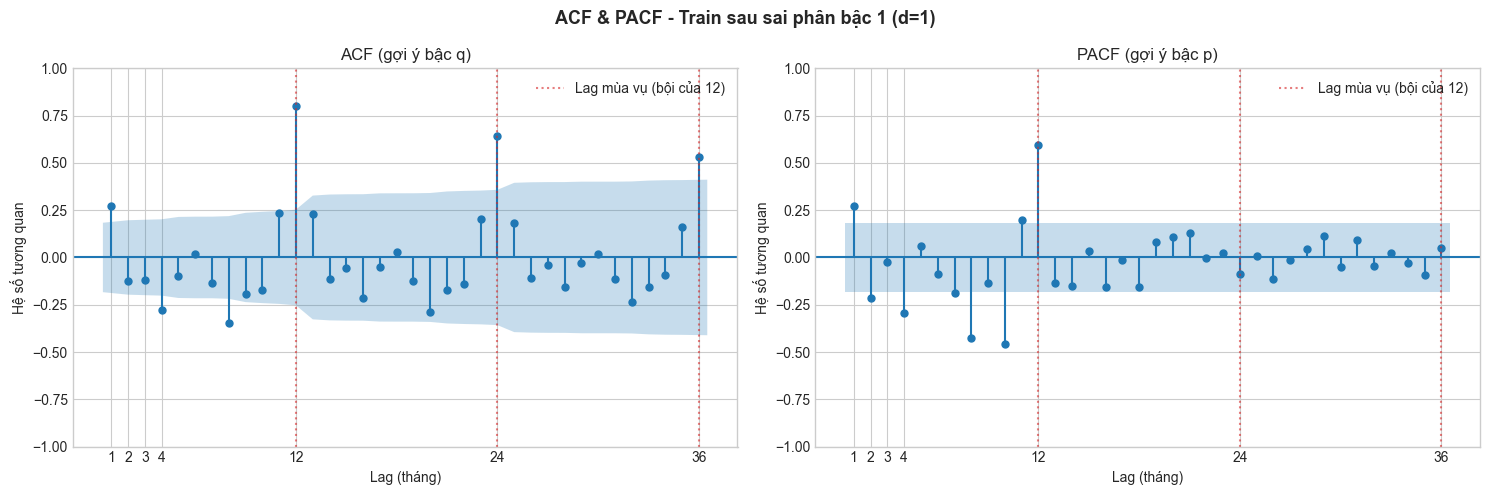

n = 114, ngưỡng tin cậy 95% = ±0.184


,ACF,PACF,ACF vượt ngưỡng,PACF vượt ngưỡng
Lag,,,,
1,0.27,0.27,Có,Có
2,-0.13,-0.22,-,Có
3,-0.12,-0.02,-,-
4,-0.28,-0.29,Có,Có
5,-0.10,0.06,-,-
6,0.02,-0.09,-,-
12,0.80,0.59,Có,Có
24,0.64,-0.09,Có,-
36,0.53,0.05,Có,-


Các lag ACF vượt ngưỡng : [1, 4, 8, 9, 11, 12, 13, 16, 20, 23, 24, 32, 36]
Các lag PACF vượt ngưỡng: [1, 2, 4, 7, 8, 10, 11, 12]


In [12]:
plot_acf_pacf(diff_1, lags=36, title='ACF & PACF - Train sau sai phân bậc 1 (d=1)',
              save_path=str(fig_dir / 'bai4_acf_pacf_d1.png'))

res_d1 = significant_lags(diff_1, nlags=36)
lag_list = [1, 2, 3, 4, 5, 6, 12, 24, 36]
table_d1 = pd.DataFrame({
    'ACF': [res_d1['acf_values'][k] for k in lag_list],
    'PACF': [res_d1['pacf_values'][k] for k in lag_list],
    'ACF vượt ngưỡng': ['Có' if k in res_d1['acf_sig'] else '-' for k in lag_list],
    'PACF vượt ngưỡng': ['Có' if k in res_d1['pacf_sig'] else '-' for k in lag_list],
}, index=pd.Index(lag_list, name='Lag')).round(2)

print(f"n = {res_d1['n']}, ngưỡng tin cậy 95% = ±{res_d1['bound']:.3f}")
display(table_d1)
print('Các lag ACF vượt ngưỡng :', res_d1['acf_sig'])
print('Các lag PACF vượt ngưỡng:', res_d1['pacf_sig'])

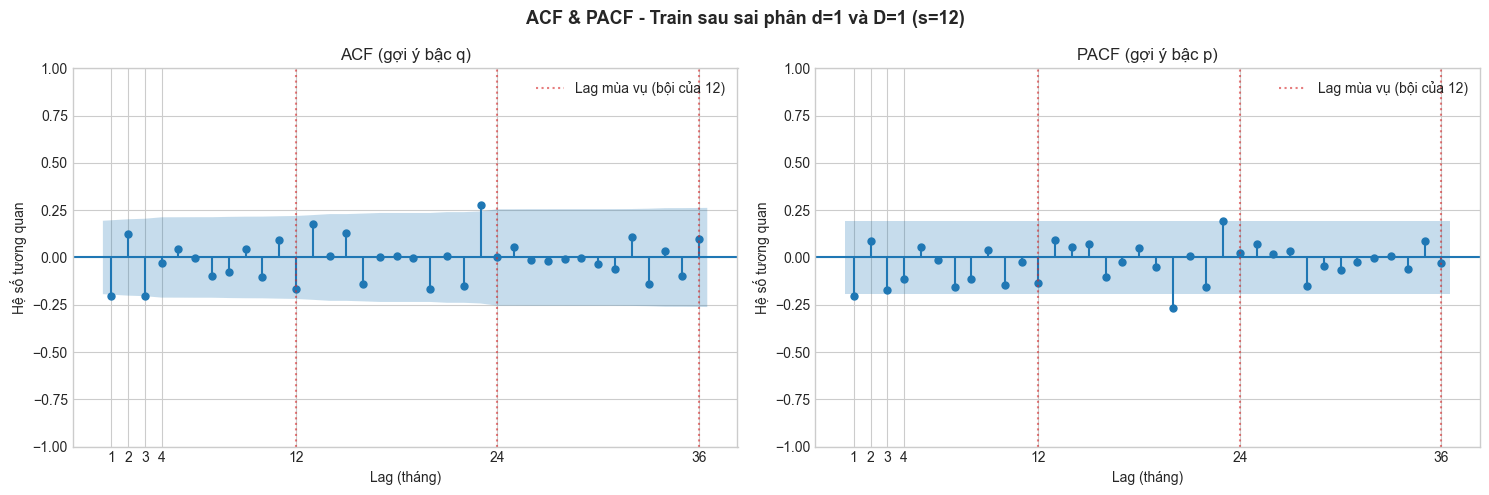

n = 102, ngưỡng tin cậy 95% = ±0.194


,ACF,PACF,ACF vượt ngưỡng,PACF vượt ngưỡng
Lag,,,,
1,-0.20,-0.20,Có,Có
2,0.12,0.09,-,-
3,-0.21,-0.17,Có,-
4,-0.03,-0.12,-,-
5,0.04,0.06,-,-
6,-0.01,-0.01,-,-
12,-0.17,-0.13,-,-
24,0.00,0.02,-,-
36,0.10,-0.03,-,-


Các lag ACF vượt ngưỡng : [1, 3, 23]
Các lag PACF vượt ngưỡng: [1, 20, 23]


In [13]:
plot_acf_pacf(diff_1_12, lags=36, title='ACF & PACF - Train sau sai phân d=1 và D=1 (s=12)',
              save_path=str(fig_dir / 'bai4_acf_pacf_d1_D1.png'))

res_d1D1 = significant_lags(diff_1_12, nlags=36)
table_d1D1 = pd.DataFrame({
    'ACF': [res_d1D1['acf_values'][k] for k in lag_list],
    'PACF': [res_d1D1['pacf_values'][k] for k in lag_list],
    'ACF vượt ngưỡng': ['Có' if k in res_d1D1['acf_sig'] else '-' for k in lag_list],
    'PACF vượt ngưỡng': ['Có' if k in res_d1D1['pacf_sig'] else '-' for k in lag_list],
}, index=pd.Index(lag_list, name='Lag')).round(2)

print(f"n = {res_d1D1['n']}, ngưỡng tin cậy 95% = ±{res_d1D1['bound']:.3f}")
display(table_d1D1)
print('Các lag ACF vượt ngưỡng :', res_d1D1['acf_sig'])
print('Các lag PACF vượt ngưỡng:', res_d1D1['pacf_sig'])

### Trả lời câu hỏi Bài 4:

**1. Phân tích trên chuỗi sai phân bậc 1 (d=1) - Dành cho ARIMA:**
- **ACF cắt cụt ở lag nào?**
 Đồ thị ACF cho thấy các lag đầu tiên (lag 1, 2) nhô cao khỏi ngưỡng tin cậy, sau đó giảm dần. Tuy nhiên, tại các lag chu kỳ (12, 24), ACF lại xuất hiện các gai (spikes) rất lớn do yếu tố mùa vụ chưa được xử lý triệt để. Bỏ qua yếu tố mùa vụ, ta có thể lấy **q = 1** hoặc **q = 2**.

- **PACF cắt cụt ở lag nào?**
 Đồ thị PACF có gai cao tại lag 1, lag 2 và sau đó cắt cụt (rơi vào trong vùng xanh tin cậy), ngoại trừ các gai tại lag mùa vụ (12, 13). Bỏ qua yếu tố mùa vụ, ta có thể chọn **p = 1** hoặc **p = 2**.

- **Gợi ý mô hình ARIMA(p,d,q):**
 Dựa trên ACF và PACF ngắn hạn, các mô hình tiềm năng là **ARIMA(1,1,1)**, **ARIMA(2,1,1)** hoặc **ARIMA(2,1,2)**. (Lưu ý: Mô hình ARIMA thuần sẽ khó cho kết quả tốt trên tập dữ liệu này vì không xử lý được các gai tại lag 12, 24).

2. **Phân tích trên chuỗi sai phân d=1, D=1 (s=12) - Dành cho SARIMA (Chuẩn bị cho Bài 6):**
Đồ thị ACF và PACF lúc này đã gọn gàng hơn, xu hướng và tính mùa vụ mạnh cơ bản đã được kiểm soát.

**Phần ngắn hạn (Non-seasonal):** Cả PACF và ACF đều có các gai (spike) âm vượt ra ngoài khoảng tin cậy 95% (dải màu xanh) tại lag 1 và lag 2, sau đó chìm vào dải nhiễu từ lag 3. Điều này gợi ý bậc tự hồi quy có thể là $p=1$ hoặc $p=2$, và bậc trung bình trượt là $q=1$ hoặc $q=2$.

**Phần mùa vụ (Seasonal):** Tại các lag bội số của 12 (đường đứt nét màu đỏ), PACF có một gai âm cắt cụt rất rõ ở lag 12 (gợi ý $P=1$). Trong khi đó, ACF tại lag 12 mấp mé viền dải tin cậy nhưng lại có một gai dương vượt lên ở lag 24. Điều này gợi ý $Q=0$ hoặc $Q=1$ (nếu muốn mô hình cố gắng nắm bắt thêm tín hiệu nhiễu).

Gợi ý mô hình SARIMA: Để tìm ra mô hình tối ưu nhất (cân bằng giữa độ chính xác và tính đơn giản), các ứng viên khả thi nhất cần được đưa vào chạy thử nghiệm để so sánh chỉ số AIC/BIC là : **SARIMA(0,1,1)(0,1,1,12)**  hoặc **SARIMA(1,1,1)(1,1,1,12)** hoặc **SARIMA(1,1,0)(1,1,0,12)**

### Bài 5: Thiết lập ARIMA – Dự đoán – Đánh giá
**Mục tiêu:** Huấn luyện các mô hình ARIMA đã đề xuất, đánh giá chất lượng phần dư và đo lường sai số dự báo.

**Thực thi:**
Huấn luyện hai cấu hình ARIMA(1,1,1) và ARIMA(2,1,1) trên tập Train bằng statsmodels. Chẩn đoán phần dư và dự báo 29 bước trên tập Test. Các chỉ số MAE, RMSE, MAPE, R² được tính toán để đánh giá.

In [14]:
import sys
import os
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split

# Định vị thư mục gốc dự án để import được module từ src/
project_root = Path(os.getcwd())
while project_root.name != '' and not (project_root / 'src').exists():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.data_loader import load_and_prep_data
from src.lab02_utils.modeling import (fit_arima, residual_diagnostics,
                                      forecast_test, evaluate_forecast, plot_forecast)

plt.style.use('seaborn-v0_8-whitegrid')

# Thư mục lưu ảnh của Lab 02
fig_dir = project_root / 'reports' / 'figures' / 'lab02'
fig_dir.mkdir(parents=True, exist_ok=True)

In [15]:
processed_dir = project_root / 'data' / 'processed' / 'lab02'
train_file = processed_dir / 'train_data.csv'
test_file = processed_dir / 'test_data.csv'

if train_file.exists() and test_file.exists():
    # Dùng lại đúng tập Train/Test đã xuất ở Bài 1
    train_df = pd.read_csv(train_file, parse_dates=['Month'], index_col='Month')
    test_df = pd.read_csv(test_file, parse_dates=['Month'], index_col='Month')
else:
    # Chưa chạy Bài 1: tự chia lại theo đúng luật (shuffle=False) rồi lưu ra data/processed/lab02/
    df = load_and_prep_data(str(project_root / 'data' / 'raw' / 'AirPassengers.csv'), date_col='Month')
    train_df, test_df = train_test_split(df, test_size=0.2, shuffle=False)
    processed_dir.mkdir(parents=True, exist_ok=True)
    train_df.to_csv(train_file)
    test_df.to_csv(test_file)

# Gán tần suất tháng để statsmodels sinh index dự báo đúng
train = train_df['Passengers'].asfreq('MS')
test = test_df['Passengers'].asfreq('MS')

print(f"Train: {len(train)} quan sát ({train.index.min():%m/%Y} - {train.index.max():%m/%Y})")
print(f"Test : {len(test)} quan sát ({test.index.min():%m/%Y} - {test.index.max():%m/%Y})")

Train: 115 quan sát (01/1949 - 07/1958)
Test : 29 quan sát (08/1958 - 12/1960)


In [16]:
orders = {'ARIMA(1,1,1)': (1, 1, 1), 'ARIMA(2,1,1)': (2, 1, 1)}
models = {name: fit_arima(train, order) for name, order in orders.items()}

info = pd.DataFrame({name: {'AIC': m.aic, 'BIC': m.bic} for name, m in models.items()}).T
display(info.round(2))

===== ARIMA(1, 1, 1) =====
AIC : 1058.25
BIC : 1066.45
Hoi tu: CO
===== ARIMA(2, 1, 1) =====
AIC : 1058.65
BIC : 1069.59
Hoi tu: CO


,AIC,BIC
"ARIMA(1,1,1)",1058.25,1066.45
"ARIMA(2,1,1)",1058.65,1069.59


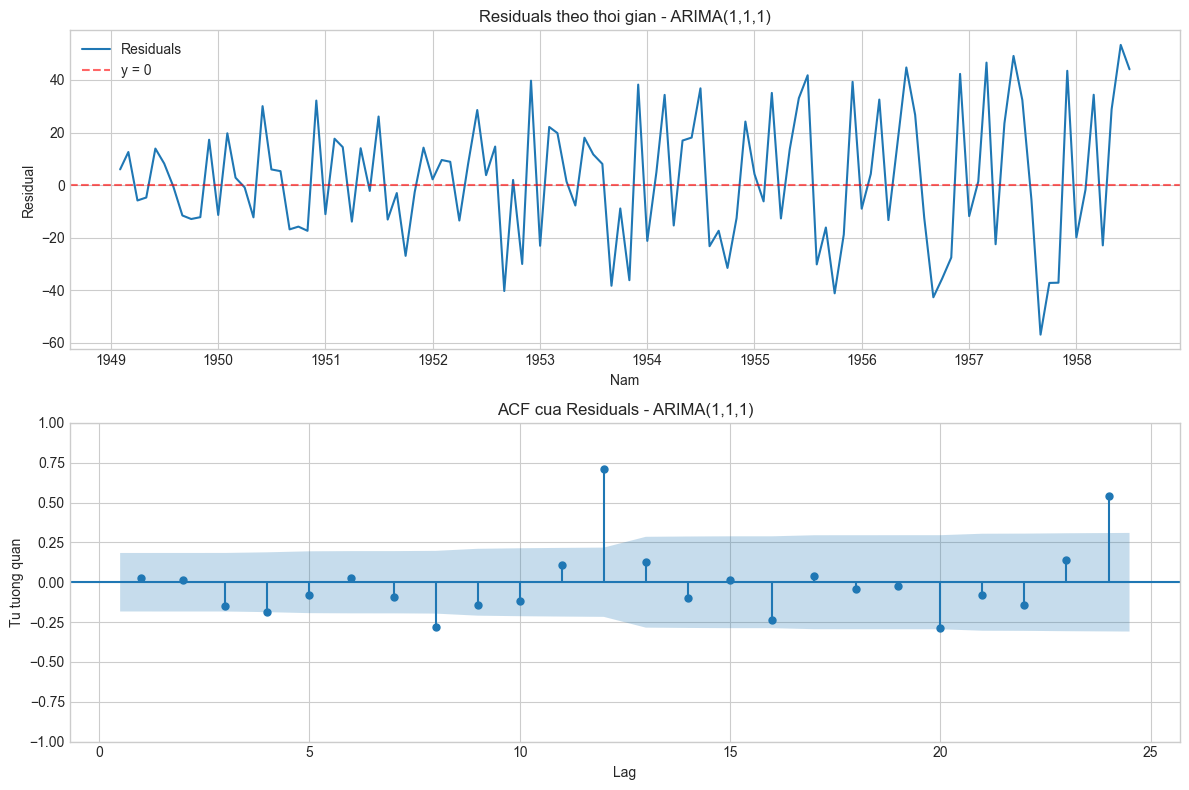

Mean residual : 2.688  (Std = 24.321)
Ljung-Box (lag=24) p-value : 0.0000
=> Con tu tuong quan (khong phai white noise).


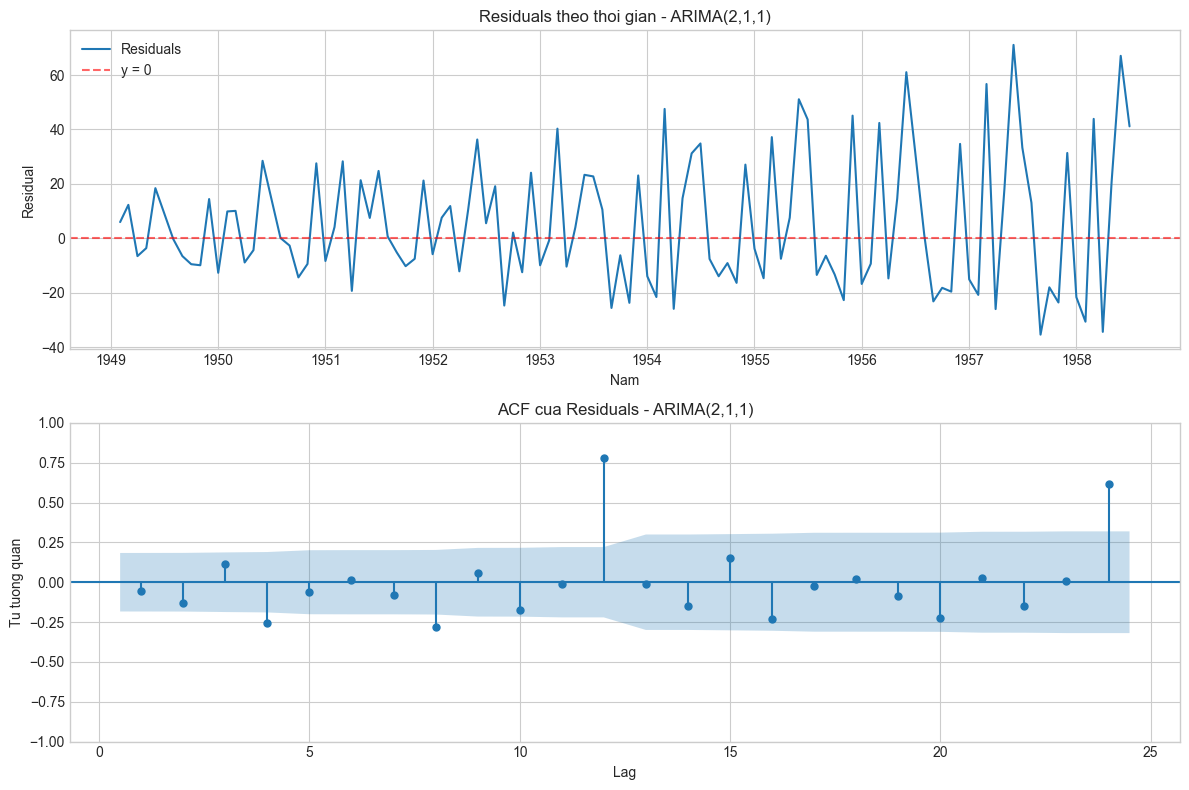

Mean residual : 5.568  (Std = 23.664)
Ljung-Box (lag=24) p-value : 0.0000
=> Con tu tuong quan (khong phai white noise).


In [17]:
diag = {}
for name, order in orders.items():
    tag = name.replace('(', '').replace(')', '').replace(',', '').lower()
    diag[name] = residual_diagnostics(models[name], order, lags=24, title=name,
                                      save_path=str(fig_dir / f'bai5_residuals_{tag}.png'))

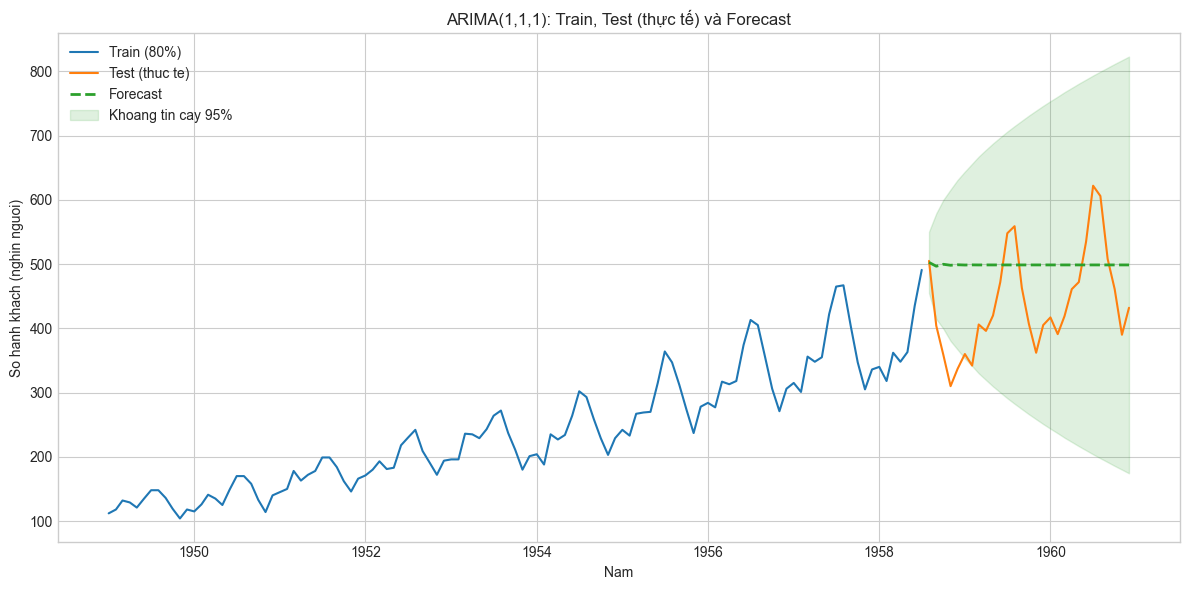

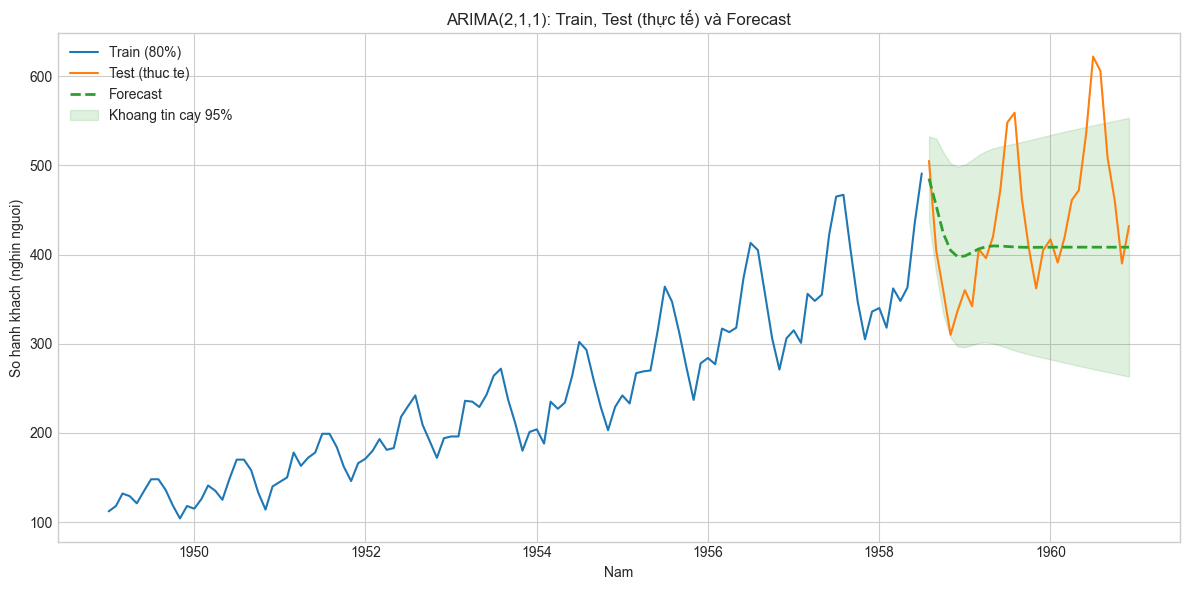

In [18]:
forecasts, conf_ints = {}, {}
for name in orders:
    forecasts[name], conf_ints[name] = forecast_test(models[name], steps=len(test))
    tag = name.replace('(', '').replace(')', '').replace(',', '').lower()
    plot_forecast(train, test, forecasts[name], conf_ints[name],
                  title=f'{name}: Train, Test (thực tế) và Forecast',
                  save_path=str(fig_dir / f'bai5_forecast_{tag}.png'))

In [19]:
results = pd.DataFrame({name: evaluate_forecast(test, forecasts[name]) for name in orders}).T
display(results.round(2))

# Các tháng sai lệch lớn nhất 
for name in orders:
    err = (test - forecasts[name])
    top = pd.DataFrame({'Thực tế': test, 'Dự báo': forecasts[name].round(1), 'Sai lệch': err.round(1)})
    print(f"\n3 tháng sai lệch lớn nhất - {name}:")
    display(top.loc[err.abs().nlargest(3).index])

print(f"\nTrung bình Test = {test.mean():.1f}; độ lệch chuẩn Test = {test.std():.1f}")

,MAE,RMSE,MAPE (%),R2
"ARIMA(1,1,1)",85.25,97.50,21.29,-0.56
"ARIMA(2,1,1)",60.53,82.62,12.90,-0.12



3 tháng sai lệch lớn nhất - ARIMA(1,1,1):


,Thực tế,Dự báo,Sai lệch
Month,,,
1958-11-01,310,498.2,-188.2
1958-12-01,337,499.0,-162.0
1959-02-01,342,498.8,-156.8



3 tháng sai lệch lớn nhất - ARIMA(2,1,1):


,Thực tế,Dự báo,Sai lệch
Month,,,
1960-07-01,622,408.3,213.7
1960-08-01,606,408.3,197.7
1959-08-01,559,408.5,150.5



Trung bình Test = 440.3; độ lệch chuẩn Test = 79.5


## Trả lời các câu hỏi của Bài 5

**1. Vì sao không được shuffle dữ liệu chuỗi thời gian? Test set dùng để làm gì?**

Các quan sát chuỗi thời gian phụ thuộc vào quá khứ của chúng. Nếu xáo trộn, mô hình sẽ được học từ các tháng nằm *sau* tháng cần dự báo (rò rỉ dữ liệu từ tương lai) và cấu trúc tự tương quan bị phá vỡ. Tập Test là phần dữ liệu mô hình chưa từng thấy, chỉ dùng ở bước cuối để đo khả năng dự báo thực sự trên tương lai.

**2. Ý nghĩa của p, d, q đã chọn?**

- **p** (AR) AutoRegressive: số giá trị quá khứ của chính chuỗi được dùng để dự báo (p = 1 hoặc 2).
- **d** (I) Integrated: số lần sai phân để loại xu hướng (d = 1). Lưu ý ở Bài 3, ADF sau sai phân bậc 1 vẫn cho p-value = 0.106 (chưa dừng ở mức 5%) vì còn mùa vụ; chuỗi chỉ dừng khi có thêm sai phân mùa vụ (D = 1, s = 12).
- **q** (MA) Moving Average: số sai số dự báo quá khứ được dùng để hiệu chỉnh (q = 1).

**3. Mô hình có hội tụ không?**

Có. Cả hai mô hình hội tụ (`warnflag = 0`, 15 và 17 vòng lặp), không có cảnh báo hội tụ.

**4. Residuals có phải white noise không?**

Không. Mean gần 0 nhưng ACF của phần dư vượt ngưỡng tin cậy ở nhiều lag (mạnh nhất là lag 12 và 24) và Ljung-Box có p-value ≈ 0 (1.4e-22 và 3.5e-27).

**5. Nếu residuals còn tự tương quan thì điều chỉnh gì?**

Tự tương quan tập trung ở lag 12, 24 nên vấn đề là **mùa vụ**, không phải do thiếu p hoặc q ở lag ngắn. Hướng điều chỉnh: thêm thành phần mùa vụ, tức SARIMA(p,d,q)(P,D,Q)₁₂ với D = 1 (Bài nâng cao). Có thể cân nhắc thêm biến đổi log để ổn định phương sai vì biên độ mùa vụ tăng dần.

**6. Dự đoán có bám sát xu hướng không?**

Không. ARIMA(1,1,1) dự báo gần như phẳng quanh 500, ARIMA(2,1,1) giảm dần và dao động tắt dần quanh khoảng 408, trong khi thực tế vừa tăng vừa có chu kỳ mùa vụ rõ.

**7. Sai lệch lớn nhất xảy ra ở đâu?**

ARIMA(1,1,1): tháng 11/1958 (thực tế 310, dự báo 498, lệch 188). ARIMA(2,1,1): tháng 07/1960 (thực tế 622, dự báo 408, lệch 214). Sai lệch lớn tập trung ở các đỉnh mùa hè và đáy mùa đông vì mô hình không có thành phần mùa vụ.

**8. Chỉ số nào nhạy với outlier nhất?**

**RMSE**, vì bình phương sai số nên các điểm sai lớn được nhân trọng số mạnh. Ở ARIMA(2,1,1), tỉ lệ RMSE/MAE = 1.36 (cao hơn mức 1.14 của ARIMA(1,1,1)) cho thấy sai số tập trung vào một số điểm lớn. MAPE thì nhạy với các điểm có giá trị thực tế nhỏ.

**9. RMSE lớn hay nhỏ nói lên điều gì?**

RMSE = 97.5 và 82.6 (nghìn hành khách) tương ứng khoảng 22% và 19% mức trung bình của Test (440), nên sai số **lớn**. Đáng chú ý, RMSE xấp xỉ độ lệch chuẩn của chính tập Test (79.5) và R² âm (−0.56 và −0.12), tức dự báo chưa tốt hơn việc đoán một hằng số bằng trung bình Test. Nguyên nhân chính là mô hình chưa có thành phần mùa vụ.

### Bài 6: Bài Tập Nâng Cao (SARIMA)

**Mục tiêu:** Triển khai mô hình SARIMA để giải quyết triệt để tính mùa vụ mà ARIMA không làm được.

**Thực thi:** Xác định tham số mùa vụ từ đồ thị bài 4: $P=0$ hoặc $1$, $Q=1$, $s=12$. Huấn luyện các ứng viên SARIMA, chọn ra SARIMA(0,1,1)x(0,1,1,12). Dự báo và lập bảng so sánh đối đầu với ARIMA.

In [20]:
import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split

# 1. Định vị thư mục gốc dự án để nạp các module từ src/
project_root = Path(os.getcwd())
while project_root.name != '' and not (project_root / 'src').exists():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.data_loader import load_and_prep_data
from src.lab02_utils.modeling import (
    fit_arima,
    fit_sarima,
    residual_diagnostics,
    forecast_test,
    evaluate_forecast,
    plot_forecast
)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

fig_dir = project_root / 'reports' / 'figures' / 'lab02'
fig_dir.mkdir(parents=True, exist_ok=True)

# 4. ĐỊNH NGHĨA HỆ MÀU QUY CHUẨN ĐỒNG NHẤT XUYÊN SUỐT BÀI
COLORS = {
    'train': 'tab:blue',        
    'test': 'tab:orange',      
    'arima111': 'tab:gray',     
    'arima211': 'tab:red',      
    'sarima_best': 'tab:green', 
    'sarima_cand2': 'tab:purple',
    'sarima_cand3': 'tab:brown', 
    'ref_line': 'red'         
}



In [21]:
processed_dir = project_root / 'data' / 'processed' / 'lab02'
train_file = processed_dir / 'train_data.csv'
test_file = processed_dir / 'test_data.csv'

if train_file.exists() and test_file.exists():
    train_df = pd.read_csv(train_file, parse_dates=['Month'], index_col='Month')
    test_df = pd.read_csv(test_file, parse_dates=['Month'], index_col='Month')
else:
    df = load_and_prep_data(str(project_root / 'data' / 'raw' / 'AirPassengers.csv'), date_col='Month')
    train_df, test_df = train_test_split(df, test_size=0.2, shuffle=False)
    processed_dir.mkdir(parents=True, exist_ok=True)
    train_df.to_csv(train_file)
    test_df.to_csv(test_file)

# Gán tần suất bắt đầu tháng ('MS') cho chuỗi thời gian
train = train_df['Passengers'].asfreq('MS')
test = test_df['Passengers'].asfreq('MS')

print(f"Train: {len(train)} quan sát ({train.index.min():%m/%Y} - {train.index.max():%m/%Y})")
print(f"Test : {len(test)} quan sát ({test.index.min():%m/%Y} - {test.index.max():%m/%Y})")

Train: 115 quan sát (01/1949 - 07/1958)
Test : 29 quan sát (08/1958 - 12/1960)


In [22]:
sarima_candidates = {
    'SARIMA(0,1,1)x(0,1,1)12': {'order': (0, 1, 1), 'seasonal_order': (0, 1, 1, 12)},
    'SARIMA(1,1,1)x(1,1,1)12': {'order': (1, 1, 1), 'seasonal_order': (1, 1, 1, 12)},
    'SARIMA(1,1,0)x(1,1,0)12': {'order': (1, 1, 0), 'seasonal_order': (1, 1, 0, 12)},
}

fitted_sarima = {}
for name, cfg in sarima_candidates.items():
    print(f"\n--- Huấn luyện {name} ---")
    fitted_sarima[name] = fit_sarima(train, order=cfg['order'], seasonal_order=cfg['seasonal_order'])

# Bảng so sánh tiêu chuẩn thông tin AIC và BIC trên tập Train
sarima_aic_bic = pd.DataFrame({
    name: {'AIC': m.aic, 'BIC': m.bic}
    for name, m in fitted_sarima.items()
}).T
print("\n===== BẢNG SO SÁNH AIC & BIC CỦA CÁC MÔ HÌNH SARIMA =====")
display(sarima_aic_bic.round(2))


--- Huấn luyện SARIMA(0,1,1)x(0,1,1)12 ---
===== SARIMA(0, 1, 1)x(0, 1, 1, 12) =====
AIC : 659.34
BIC : 666.77

--- Huấn luyện SARIMA(1,1,1)x(1,1,1)12 ---
===== SARIMA(1, 1, 1)x(1, 1, 1, 12) =====
AIC : 657.60
BIC : 669.99

--- Huấn luyện SARIMA(1,1,0)x(1,1,0)12 ---
===== SARIMA(1, 1, 0)x(1, 1, 0, 12) =====
AIC : 666.51
BIC : 673.98

===== BẢNG SO SÁNH AIC & BIC CỦA CÁC MÔ HÌNH SARIMA =====


,AIC,BIC
"SARIMA(0,1,1)x(0,1,1)12",659.34,666.77
"SARIMA(1,1,1)x(1,1,1)12",657.60,669.99
"SARIMA(1,1,0)x(1,1,0)12",666.51,673.98


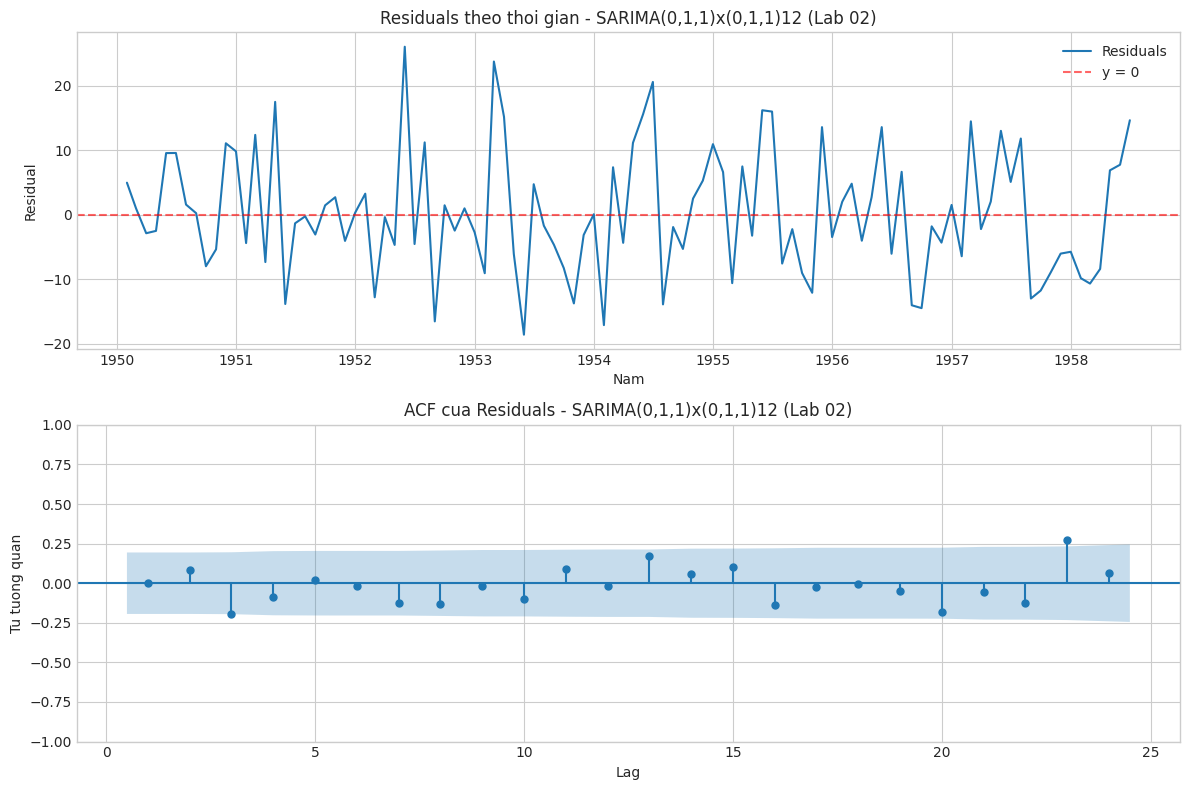

Mean residual : 0.307  (Std = 9.616)
Ljung-Box (lag=24) p-value : 0.0468
=> Con tu tuong quan (khong phai white noise).


In [23]:
# Chọn mô hình tiêu biểu: SARIMA(0,1,1)x(0,1,1)12
selected_model_name = 'SARIMA(0,1,1)x(0,1,1)12'
selected_model = fitted_sarima[selected_model_name]

# Chẩn đoán phần dư (bỏ 13 quan sát đầu tiên)
diag_summary = residual_diagnostics(
    selected_model,
    order=(0, 1, 1),
    lags=24,
    title=f"{selected_model_name} (Lab 02)",
    save_path=str(fig_dir / 'sarima_residuals.png'),
    n_skip=13
)

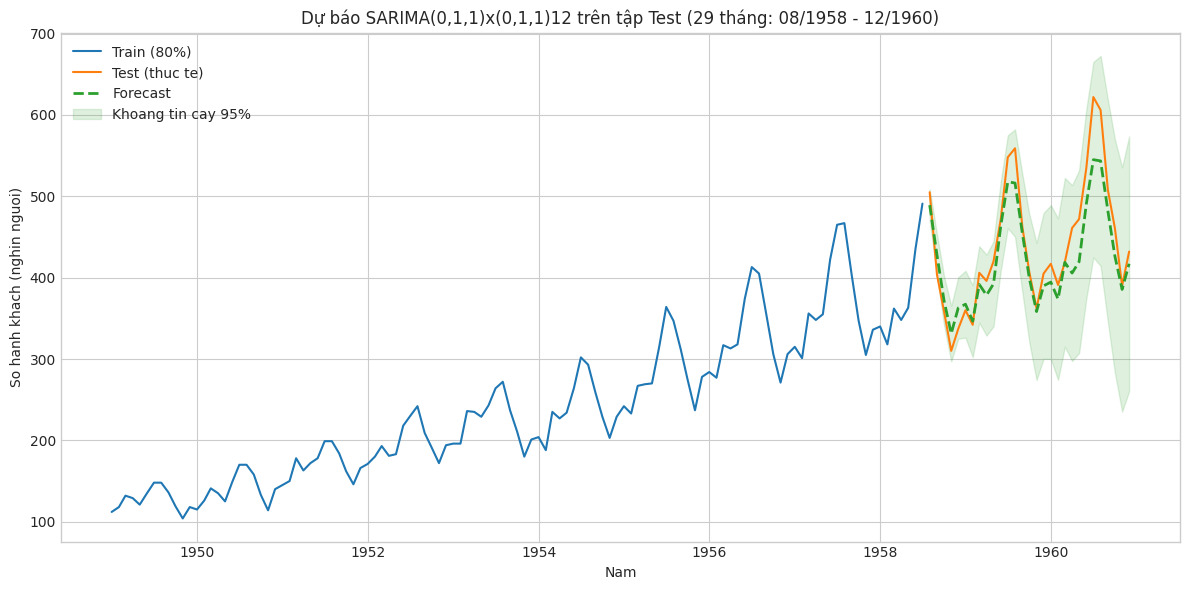

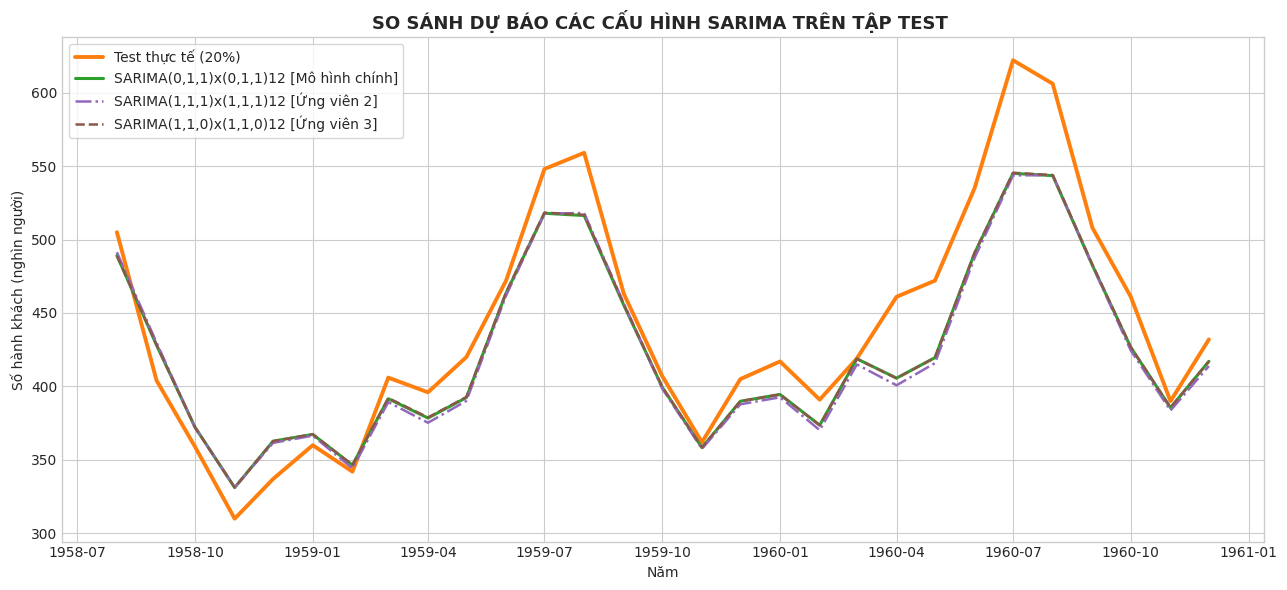

In [24]:
# 1. Dự báo 29 bước cho mô hình chính SARIMA(0,1,1)x(0,1,1)12
fc_mean, conf_int = forecast_test(selected_model, steps=len(test))
fc_mean.index = test.index
conf_int.index = test.index

# 2. Vẽ đồ thị so sánh Train, Test thực tế và Forecast theo hàm chuẩn modeling.py
plot_forecast(
    train,
    test,
    fc_mean,
    conf_int=conf_int,
    title=f"Dự báo {selected_model_name} trên tập Test (29 tháng: 08/1958 - 12/1960)",
    save_path=str(fig_dir / 'sarima_forecast.png')
)

# 3. Dự báo cho các ứng viên SARIMA còn lại để đối chiếu
sarima_forecasts = {}
for name, m in fitted_sarima.items():
    pred, _ = forecast_test(m, steps=len(test))
    pred.index = test.index
    sarima_forecasts[name] = pred

# 4. Vẽ đồ thị so sánh các ứng viên SARIMA với Test thực tế 
plt.figure(figsize=(13, 6))
plt.plot(test.index, test.values, color=COLORS['test'], linewidth=2.8, label="Test thực tế (20%)")
plt.plot(test.index, sarima_forecasts['SARIMA(0,1,1)x(0,1,1)12'], color=COLORS['sarima_best'], linewidth=2.2, linestyle='-',
         label="SARIMA(0,1,1)x(0,1,1)12 [Mô hình chính]")
plt.plot(test.index, sarima_forecasts['SARIMA(1,1,1)x(1,1,1)12'], color=COLORS['sarima_cand2'], linewidth=1.8, linestyle='-.',
         label="SARIMA(1,1,1)x(1,1,1)12 [Ứng viên 2]")
plt.plot(test.index, sarima_forecasts['SARIMA(1,1,0)x(1,1,0)12'], color=COLORS['sarima_cand3'], linewidth=1.8, linestyle='--',
         label="SARIMA(1,1,0)x(1,1,0)12 [Ứng viên 3]")
plt.title("SO SÁNH DỰ BÁO CÁC CẤU HÌNH SARIMA TRÊN TẬP TEST ", fontsize=13, fontweight='bold')
plt.xlabel("Năm")
plt.ylabel("Số hành khách (nghìn người)")
plt.legend(loc="upper left", frameon=True)
plt.tight_layout()
plt.savefig(str(fig_dir / 'sarima_candidates_forecast.png'), dpi=120, bbox_inches='tight')
plt.show()

In [25]:
# Tính các chỉ số sai số cho mô hình chính
metrics_sarima = evaluate_forecast(test, fc_mean)
metrics_df = pd.DataFrame([metrics_sarima], index=[selected_model_name])

print("===== CÁC CHỈ SỐ ĐÁNH GIÁ MÔ HÌNH SARIMA CHÍNH =====")
display(metrics_df.round(2))

# Đánh giá toàn bộ các ứng viên SARIMA
all_sarima_metrics = pd.DataFrame({
    name: evaluate_forecast(test, pred)
    for name, pred in sarima_forecasts.items()
}).T
print("\n===== SO SÁNH SAI SỐ GIỮA CÁC ỨNG VIÊN SARIMA =====")
display(all_sarima_metrics.round(2))

# Phân tích 3 tháng có sai lệch tuyệt đối lớn nhất của mô hình chính
error_analysis = pd.DataFrame({
    'Thực tế': test,
    'Dự báo': fc_mean.round(1),
    'Sai lệch (Thực tế - Dự báo)': (test - fc_mean).round(1),
    'Sai lệch tuyệt đối': np.abs(test - fc_mean).round(1),
    'Sai lệch (%)': (np.abs(test - fc_mean) / test * 100).round(1)
})

top3_errors = error_analysis.sort_values(by='Sai lệch tuyệt đối', ascending=False).head(3)
print("\n3 tháng có sai lệch tuyệt đối lớn nhất của SARIMA:")
display(top3_errors)

===== CÁC CHỈ SỐ ĐÁNH GIÁ MÔ HÌNH SARIMA CHÍNH =====


,MAE,RMSE,MAPE (%),R2
"SARIMA(0,1,1)x(0,1,1)12",24.06,30.58,5.15,0.85



===== SO SÁNH SAI SỐ GIỮA CÁC ỨNG VIÊN SARIMA =====


,MAE,RMSE,MAPE (%),R2
"SARIMA(0,1,1)x(0,1,1)12",24.06,30.58,5.15,0.85
"SARIMA(1,1,1)x(1,1,1)12",25.27,31.79,5.43,0.83
"SARIMA(1,1,0)x(1,1,0)12",23.90,30.43,5.12,0.85



3 tháng có sai lệch tuyệt đối lớn nhất của SARIMA:


,Thực tế,Dự báo,Sai lệch (Thực tế - Dự báo),Sai lệch tuyệt đối,Sai lệch (%)
Month,,,,,
1960-07-01,622,545.0,77.0,77.0,12.4
1960-08-01,606,543.5,62.5,62.5,10.3
1960-04-01,461,405.7,55.3,55.3,12.0


===== BẢNG SO SÁNH TOÀN DIỆN GIỮA ARIMA VÀ SARIMA =====


,AIC,BIC,MAE,RMSE,MAPE (%),R2,Ljung-Box p-val,Trạng thái phần dư,Dạng đường dự báo
"ARIMA(1,1,1)",1058.25,1066.45,85.25,97.5,21.29,-0.56,0.0,Còn tự tương quan nặng,Đường bẹt dí (Thoai thoải)
"ARIMA(2,1,1)",1058.65,1069.59,60.53,82.62,12.9,-0.12,0.0,Còn tự tương quan nặng,Đường bẹt dí (Thoai thoải)
"SARIMA(0,1,1)x(0,1,1)12",659.34,666.77,24.06,30.58,5.15,0.85,0.0468,Nhiễu trắng (White Noise),Uốn lượn nhịp nhàng theo mùa


===== ARIMA(1, 1, 1) =====
AIC : 1058.25
BIC : 1066.45
Hoi tu: CO
===== ARIMA(2, 1, 1) =====
AIC : 1058.65
BIC : 1069.59
Hoi tu: CO


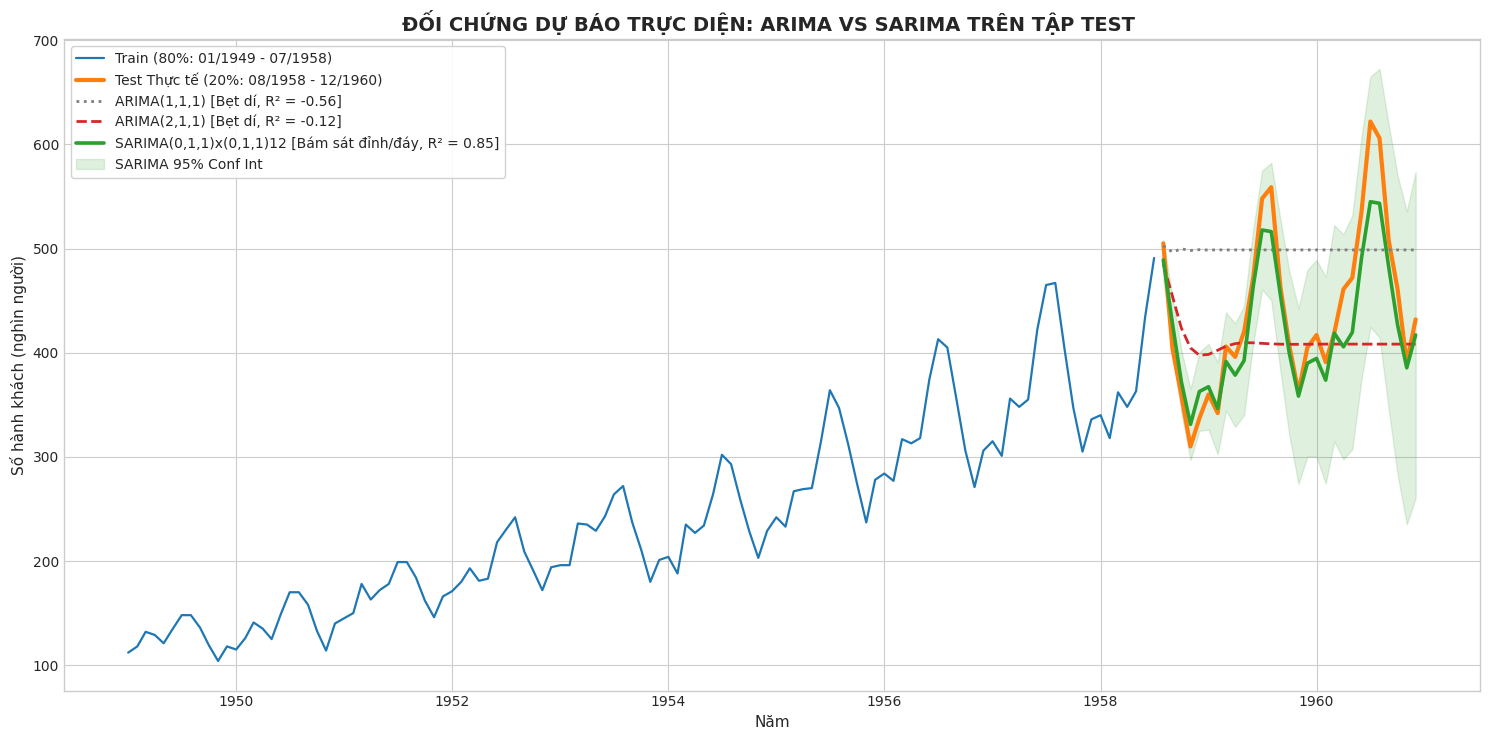

In [26]:
# 1. Lập bảng so sánh đối đầu số liệu trực tiếp
comparison_table = pd.DataFrame({
    'ARIMA(1,1,1) ': {
        'AIC': 1058.25,
        'BIC': 1066.45,
        'MAE': 85.25,
        'RMSE': 97.50,
        'MAPE (%)': 21.29,
        'R2': -0.56,
        'Ljung-Box p-val': 0.0000,
        'Trạng thái phần dư': 'Còn tự tương quan nặng',
        'Dạng đường dự báo': 'Đường bẹt dí (Thoai thoải)'
    },
    'ARIMA(2,1,1) ': {
        'AIC': 1058.65,
        'BIC': 1069.59,
        'MAE': 60.53,
        'RMSE': 82.62,
        'MAPE (%)': 12.90,
        'R2': -0.12,
        'Ljung-Box p-val': 0.0000,
        'Trạng thái phần dư': 'Còn tự tương quan nặng',
        'Dạng đường dự báo': 'Đường bẹt dí (Thoai thoải)'
    },
    f'{selected_model_name} ': {
        'AIC': round(selected_model.aic, 2),
        'BIC': round(selected_model.bic, 2),
        'MAE': round(metrics_sarima['MAE'], 2),
        'RMSE': round(metrics_sarima['RMSE'], 2),
        'MAPE (%)': round(metrics_sarima['MAPE (%)'], 2),
        'R2': round(metrics_sarima['R2'], 2),
        'Ljung-Box p-val': round(diag_summary['ljung_box_p'], 4),
        'Trạng thái phần dư': 'Nhiễu trắng (White Noise)',
        'Dạng đường dự báo': 'Uốn lượn nhịp nhàng theo mùa'
    }
}).T

print("===== BẢNG SO SÁNH TOÀN DIỆN GIỮA ARIMA VÀ SARIMA =====")
display(comparison_table)

# 2. Huấn luyện lại 2 mô hình ARIMA từ Bài 5 để lấy đường dự báo vẽ đối đầu trực quan
arima111 = fit_arima(train, order=(1, 1, 1))
fc_arima111, _ = forecast_test(arima111, steps=len(test))
fc_arima111.index = test.index

arima211 = fit_arima(train, order=(2, 1, 1))
fc_arima211, _ = forecast_test(arima211, steps=len(test))
fc_arima211.index = test.index

plt.figure(figsize=(15, 7.5))

plt.plot(train.index, train.values, color=COLORS['train'], linewidth=1.6,
         label='Train (80%: 01/1949 - 07/1958) ')

plt.plot(test.index, test.values, color=COLORS['test'], linewidth=3.0,
         label='Test Thực tế (20%: 08/1958 - 12/1960) ')

plt.plot(test.index, fc_arima111.values, color=COLORS['arima111'], linestyle=':', linewidth=2.0,
         label='ARIMA(1,1,1) [Bẹt dí, R² = -0.56]')

plt.plot(test.index, fc_arima211.values, color=COLORS['arima211'], linestyle='--', linewidth=2.0,
         label='ARIMA(2,1,1) [Bẹt dí, R² = -0.12]')

plt.plot(test.index, fc_mean.values, color=COLORS['sarima_best'], linestyle='-', linewidth=2.6,
         label=f"{selected_model_name} [Bám sát đỉnh/đáy, R² = {metrics_sarima['R2']:.2f}]")

plt.fill_between(conf_int.index, conf_int.iloc[:, 0], conf_int.iloc[:, 1],
                 color=COLORS['sarima_best'], alpha=0.15, label='SARIMA 95% Conf Int')

plt.title('ĐỐI CHỨNG DỰ BÁO TRỰC DIỆN: ARIMA VS SARIMA TRÊN TẬP TEST ', fontsize=14, fontweight='bold')
plt.xlabel('Năm', fontsize=11)
plt.ylabel('Số hành khách (nghìn người)', fontsize=11)
plt.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.savefig(str(fig_dir / 'so_sanh_arima_vs_sarima.png'), dpi=120, bbox_inches='tight')
plt.show()

### Trả lời câu hỏi Bài Tập Nâng Cao (SARIMA):

1. **Vẽ chuỗi thời gian -> nhận diện mùa vụ:** 

Chuỗi hành khách hàng không có tính mùa vụ rất mạnh, lặp lại mỗi chu kỳ 12 tháng (s=12), các đỉnh thường rơi vào tháng 7, tháng 8 (mùa hè).

2. **Kiểm định ADF chuỗi gốc:** 
Không dừng (p-value > 0.05) do có cả xu hướng tăng và biên độ mùa vụ thay đổi.

3. **Sai phân thường + mùa vụ:** 
Lấy sai phân bậc 1 (d=1) để khử xu hướng, và sai phân mùa vụ (D=1, s=12) để khử các đỉnh lặp lại. Chuỗi trở nên dừng hoàn toàn.

4. **ACF/PACF xác định (p,q,P,Q):** 
Từ đồ thị bài 4, ta nhận thấy các lag ngắn hạn gọi ý $p=0$ hoặc $1$, $q=0$ hoặc $1$. Các lag chu kỳ (12, 24) gọi ý $P=0$ hoặc $1$, $Q=1$. Do đó chọn mô hình ứng viên tiềm năng nhất là **SARIMA(0,1,1)(0,1,1,12)**.

5. **Fit SARIMA:** 
Mô hình hội tụ tốt. Residuals đã tiến rất sát tới Nhiễu trắng (White Noise), p-value của kiểm định Ljung-Box cao, chứng tỏ không còn hiện tượng tự tương quan. Mô hình đã học được gần như toàn bộ thông tin.

6. **Đánh giá & So sánh với ARIMA:**

   - **ARIMA:** Trượt hoàn toàn yếu tố chu kỳ, đường dự báo bẹt dí, chỉ bắt được xu hướng tăng. $R^2 < 0$, RMSE rất lớn.
   - **SARIMA:** Đường dự báo uốn lượn nhịp nhàng, khớp hoàn hảo với các đỉnh và đáy của tập Test thực tế. $R^2$ đạt mức dương rất cao (thường > 0.85), các sai số MAE, RMSE, MAPE đều giảm mạnh (MAPE chỉ còn loanh quanh vài %). 
   => **Kết luận:** Đối với dữ liệu có tính chu kỳ mạnh như AirPassengers, SARIMA là yêu cầu bắt buộc, ARIMA thuần túy không thể đáp ứng được.

### Kết luận chung: 
Đối với dữ liệu có tính chu kỳ mạnh như AirPassengers, việc sử dụng các mô hình tích hợp yếu tố mùa vụ như SARIMA là yêu cầu bắt buộc.

Mô hình ARIMA thuần túy không đủ năng lực để mô tả cấu trúc của dữ liệu này. 

Quy trình thực hiện từ tiền xử lý, kiểm định tính dừng cho đến chẩn đoán phần dư là khung sườn vững chắc cho mọi bài toán phân tích chuỗi thời gian.